# Experiment 1: when to ask

Steady asks a student two screening questions when their phone signals stay outside their own normal range. This notebook tests whether that rule picks better weeks to ask, and better weeks to send a parent a heads-up, than a fixed calendar with the same number of asks.

All the work happens in `experiments/exp1_timing.py`. This notebook imports its functions, shows the tables and draws the charts.

**Data terms.** The College Experience Study (Dartmouth) is licensed CC BY-NC-SA 4.0 for academic use. Nothing here shows a student id or a per-student row. Every table and chart is an aggregate over students.

**What the label means.** A week counts as high when the PHQ-2 score (PHQ-4 items 3 and 4) is 3 or more. A high score stands in for a note being right. It cannot show whether a note helped a family, and nothing here shows that phone signals detect depression.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(REPO / "experiments"))
import exp1_timing as ex

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)

# Light chart style
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#8f8e88"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.axisbelow": True, "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10, "legend.frameon": False,
})

def pct(x):
    return f"{100 * x:.1f}%"

## 1. The weekly table

One row per student per calendar week. A day is usable when activity and location data each cover at least 12 hours. A week is valid with at least 4 usable days, and a week short of that breaks every run. The first 4 valid weeks are the learning weeks. Every later valid week is a monitored week, and only monitored weeks can hold an ask.

The label for a week is the PHQ-2 answer nearest its end (Sunday), within 3 days either side. Those windows never overlap, so each answer labels one week at most.

In [2]:
wk = ex.build_weekly(verbose=False)
summary = ex.data_summary(wk)
pd.Series(summary, name="value").to_frame()

,value
phq2_answers,35348.000000
students_with_answers,218.000000
share_answers_positive,0.121421
median_days_between_answers,5.000000
students_with_sensing,220.000000
calendar_student_weeks,34285.000000
valid_student_weeks,23542.000000
students_analysed,213.000000
monitored_student_weeks,22688.000000
monitored_student_years,436.307692


## 2. Signals and the personal range

Each Steady signal is mapped to a feature recorded on both iPhone and Android. The personal range is the mean and spread over the learning weeks. The spread has a floor of 0.25 times the population standard deviation, so a quiet learning period cannot produce huge z-scores. z is measured in the worse direction.

In [3]:
pd.DataFrame(ex.CORE_SIGNALS)[["label", "feature", "worse", "note"]]

,label,feature,worse,note
0,Sleep,sleep_duration,lower,Mean nightly sleep (hours) from the study's sleep model. Nights scored 0 are treated as missing.
1,Bedtime regularity,sleep_start (weekly SD),higher,Standard deviation of sleep start time across the week's usable nights (hours). Needs 3 or more nights. A start code...
2,Phone use after midnight,unlock_duration_hr_0..hr_4,higher,"Minutes the phone was unlocked between midnight and 5 AM, summed per day, averaged over the week."
3,Time with others,loc_social_dur + loc_other_dorm_dur,lower,"Hours a day at social places plus other students' dorms. On campus only, so it falls to near zero during breaks."
4,Places visited,loc_visit_num_ep_0,lower,Number of distinct places visited per day.
5,Distance travelled,loc_dist_ep_0 (log scale),lower,"log10(1 + km travelled per day), averaged over the week. The log stops one long trip from dominating."


In [4]:
Z, range_info = ex.personal_z(wk, ex.CORE_SIGNALS)
pd.DataFrame(range_info).round(3)

,population_sd,spread_floor,share_students_at_floor
sleep,1.413,0.353,0.159
bedtime,1.114,0.279,0.131
night_phone,23.172,5.793,0.383
time_with_others,2.175,0.544,0.421
places,1.813,0.453,0.220
movement,0.498,0.125,0.229


## 3. Run every test

`run_all(write=False)` runs the whole experiment without touching the files in `results/`. The script itself writes them when run from the command line. It takes under a minute.

In [5]:
res = ex.run_all(write=False, verbose=False)
print(ex.make_headline(res))

At 21 asks per student-year, 14.6% of the drift rule's asks landed on weeks with a high mood score against 12.9% for a fixed calendar, but random weeks from the same student in the same three months did as well (14.9%), so the rule found harder stretches and did no better than chance at picking the week.


## 4. Asks at the same budget

The drift rule at k = 1.0 sets the budget: its asks per student-year. A fixed calendar asks each student at evenly spaced monitored weeks at the same overall rate. Random weeks come in three versions: any weeks; the same number of asks for each student; and the same number for each student in each calendar quarter. The last is the strictest test of whether the rule picks the right week.

Hit rate is the share of asks in a labelled week whose label is high. A low period is two or more high weeks in a row.

In [6]:
main = res["ask_comparison_by_k"]["1.0"]
rows = []
for name, key in [("Steady drift rule", "method"), ("Fixed calendar", "fixed_calendar")]:
    m = main[key]
    rows.append({"method": name, "hit rate": m["hit_rate"], "lift": m["lift"],
                 "low periods reached": m["share_episodes_reached"],
                 "high weeks asked": m["share_positive_weeks_asked"],
                 "false alarms per student-year": m["false_alarms_per_student_year"]})
for name, key in [("Random weeks", "random"), ("Random, same count per student", "random_same_students"),
                  ("Random, same count per student and quarter", "random_same_student_and_quarter")]:
    r = main[key]
    rows.append({"method": name, "hit rate": r["hit_rate"], "lift": r["hit_rate"] / main["method"]["base_rate"],
                 "low periods reached": r["share_episodes_reached"], "95% interval": f"{pct(r['ci'][0])} to {pct(r['ci'][1])}"})
print(f"Budget: {main['budget_asks_per_student_year']:.1f} asks per student-year; base rate {pct(main['method']['base_rate'])}")
d = main["method_minus_calendar"]
print(f"Rule minus calendar: {100 * d['difference']:+.1f} points (95% interval {100 * d['ci'][0]:.1f} to {100 * d['ci'][1]:.1f}, students resampled)")
pd.DataFrame(rows).round(3)

Budget: 21.4 asks per student-year; base rate 12.9%
Rule minus calendar: +1.8 points (95% interval 0.0 to 3.7, students resampled)


,method,hit rate,lift,low periods reached,high weeks asked,false alarms per student-year,95% interval
0,Steady drift rule,0.146,1.139,0.554,0.464,13.452,NaN
1,Fixed calendar,0.129,1.000,0.877,0.412,13.880,NaN
2,Random weeks,0.129,1.000,0.732,NaN,NaN,12.2% to 13.4%
3,"Random, same count per student",0.135,1.053,0.697,NaN,NaN,13.1% to 14.0%
4,"Random, same count per student and quarter",0.149,1.157,0.639,NaN,NaN,14.5% to 15.2%


In [7]:
m = main["method"]
print(f"Drift rule: {m['positive_weeks_missed']:,} of {m['positive_weeks']:,} high weeks got no ask; "
      f"{m['episodes_missed']} of {m['episodes']} low periods got none; {m['false_alarms']:,} false alarms.")
c = main["fixed_calendar"]
print(f"Calendar:   {m['positive_weeks'] - c['positive_weeks_asked']:,.0f} high weeks missed; "
      f"{c['episodes_missed']:.0f} low periods missed; {c['false_alarms']:,.0f} false alarms.")

Drift rule: 1,164 of 2,171 high weeks got no ask; 201 of 451 low periods got none; 5,869 false alarms.
Calendar:   1,277 high weeks missed; 56 low periods missed; 6,056 false alarms.


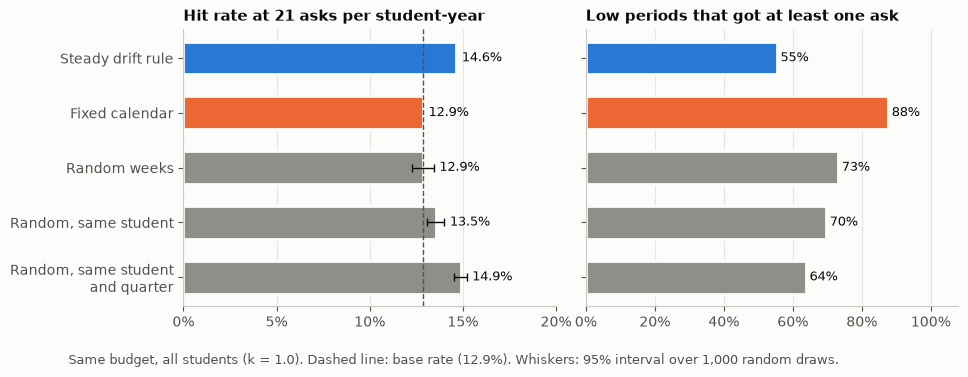

In [8]:
labels = ["Steady drift rule", "Fixed calendar", "Random weeks", "Random, same student", "Random, same student\nand quarter"]
hit = [main["method"]["hit_rate"], main["fixed_calendar"]["hit_rate"], main["random"]["hit_rate"],
       main["random_same_students"]["hit_rate"], main["random_same_student_and_quarter"]["hit_rate"]]
cis = [None, None, main["random"]["ci"], main["random_same_students"]["ci"], main["random_same_student_and_quarter"]["ci"]]
eps = [main["method"]["share_episodes_reached"], main["fixed_calendar"]["share_episodes_reached"],
       main["random"]["share_episodes_reached"], main["random_same_students"]["share_episodes_reached"],
       main["random_same_student_and_quarter"]["share_episodes_reached"]]
colors = [BLUE, ORANGE, GRAY, GRAY, GRAY]
y = np.arange(len(labels))[::-1]

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, gridspec_kw={"wspace": 0.08})
ax = axes[0]
ax.barh(y, hit, color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
for yi, h, ci in zip(y, hit, cis):
    end = h
    if ci is not None:
        ax.errorbar(h, yi, xerr=[[h - ci[0]], [ci[1] - h]], color=INK, capsize=3, lw=1)
        end = ci[1]
    ax.text(end + 0.003, yi, pct(h), va="center", ha="left", color=INK, fontsize=9)
ax.axvline(main["method"]["base_rate"], color=INK2, ls="--", lw=1)
ax.set_yticks(y, labels)
ax.set_xlim(0, 0.2)
ax.set_xticks([0, 0.05, 0.10, 0.15, 0.20])
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_title(f"Hit rate at {main['budget_asks_per_student_year']:.0f} asks per student-year")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.barh(y, eps, color=colors, height=0.6, edgecolor=SURFACE, linewidth=2)
for yi, e in zip(y, eps):
    ax.text(e + 0.01, yi, f"{100 * e:.0f}%", va="center", ha="left", color=INK, fontsize=9)
ax.set_xlim(0, 1.08)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_title("Low periods that got at least one ask")
ax.grid(axis="y", visible=False)
fig.suptitle(f"Same budget, all students (k = 1.0). Dashed line: base rate ({pct(main['method']['base_rate'])}). "
             "Whiskers: 95% interval over 1,000 random draws.",
             x=0.01, ha="left", fontsize=9, color=INK2, y=-0.02)
plt.show()

The rule's hit rate is above the calendar's, and random weeks drawn from the same student in the same quarter match it. So the gap comes from which students and which seasons the rule asks in. Within a student's quarter it picks weeks no better than chance, and because its asks bunch up it reaches fewer low periods than the calendar.

The frozen range is part of the reason. It is learned in the first four valid weeks and then drifts away from the student over the years, so the rule asks more often each year, while more students score high in later years.

,year,monitored_weeks,students,share_weeks_with_ask,asks_per_student_year,hit_rate,base_rate
0,1,9247,213,0.255,13.271,0.091,0.095
1,2,6476,175,0.437,22.724,0.167,0.152
2,3,4791,141,0.613,31.866,0.166,0.156
3,4,2174,96,0.562,29.205,0.171,0.158


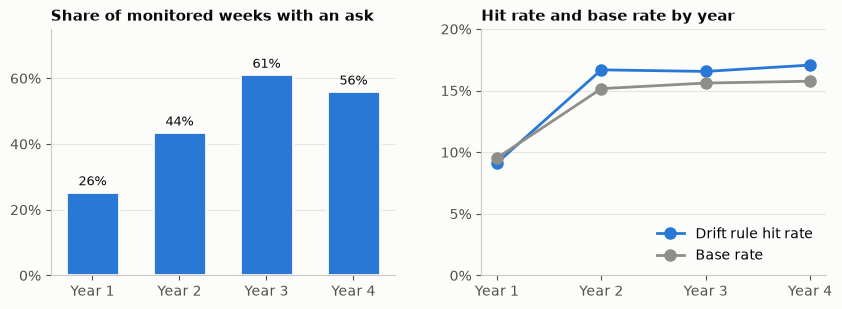

In [9]:
years = pd.DataFrame(res["rule_by_year_k1"])
display(years.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), gridspec_kw={"wspace": 0.25})
ax = axes[0]
ax.bar(years["year"], years["share_weeks_with_ask"], color=BLUE, width=0.6, edgecolor=SURFACE, linewidth=2)
for x, v in zip(years["year"], years["share_weeks_with_ask"]):
    ax.text(x, v + 0.01, f"{100 * v:.0f}%", ha="center", va="bottom", color=INK, fontsize=9)
ax.set_xticks(years["year"], [f"Year {int(v)}" for v in years["year"]])
ax.set_ylim(0, 0.75)
ax.set_yticks([0, 0.2, 0.4, 0.6])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_title("Share of monitored weeks with an ask")
ax.grid(axis="x", visible=False)

ax = axes[1]
ax.plot(years["year"], years["hit_rate"], color=BLUE, lw=2, marker="o", ms=8, label="Drift rule hit rate")
ax.plot(years["year"], years["base_rate"], color=GRAY, lw=2, marker="o", ms=8, label="Base rate")
ax.set_xticks(years["year"], [f"Year {int(v)}" for v in years["year"]])
ax.set_ylim(0, 0.2)
ax.set_yticks([0, 0.05, 0.10, 0.15, 0.20])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_title("Hit rate and base rate by year")
ax.legend(loc="lower right")
ax.grid(axis="x", visible=False)
plt.show()

## 5. Other thresholds and the adaptive range

The same comparison at k = 0.75 and k = 1.5, and with the adaptive range from concept.md (the range moves quickly toward better weeks, slowly toward worse ones, and not at all while a signal is out).

In [10]:
ex.k_table(res).round(3)

,k,asks_per_student_year,rule_hit_rate,calendar_hit_rate,random_ci_low,random_ci_high,same_students_random,rule_minus_calendar,diff_ci_low,diff_ci_high,rule_episodes_reached,calendar_episodes_reached
0,0.75,25.720,0.146,0.129,0.124,0.134,0.137,0.017,0.003,0.032,0.656,0.964
1,1.0,21.423,0.146,0.129,0.122,0.134,0.135,0.018,0.000,0.037,0.554,0.877
2,1.5,14.116,0.144,0.129,0.120,0.137,0.126,0.015,-0.014,0.049,0.361,0.689
3,1.0 adaptive,43.852,0.138,0.129,0.126,0.131,0.131,0.009,0.005,0.013,0.933,0.991


The adaptive range ratchets toward each student's best weeks, so ordinary weeks then look worse and the rule asks in most weeks. Its hit rate sits close to the base rate for that reason.

## 6. Logistic regression

Features: each signal's z this week and last week, plus the number of signals out. Students are split in half; the model is fit on one half and scored on the other. The hit rate uses the rule's budget on the same test students, taking the test weeks with the highest predicted risk. Within-student AUC compares only weeks of the same student.

In [11]:
lr_rows = []
for r in res["logistic"]["splits"]:
    lr_rows.append({"seed": r["seed"], "train AUC": r["train_auc"], "test AUC": r["test_auc"],
                    "test AUC 95% interval": f"{r['test_auc_ci'][0]:.3f} to {r['test_auc_ci'][1]:.3f}",
                    "within-student AUC": r["test_within_student_auc"],
                    "signals-out count AUC": r["test_auc_signals_out"],
                    "logistic hit rate": r["logistic_at_budget"]["hit_rate"],
                    "rule hit rate": r["rule_on_test"]["hit_rate"],
                    "calendar hit rate": r["calendar_on_test"]["hit_rate"]})
display(pd.DataFrame(lr_rows).round(3))
print("Week split instead of student split, for contrast only: AUC",
      round(res["logistic"]["week_split_contrast"]["test_auc"], 3))
lr0 = res["logistic"]["splits"][0]
pd.Series({"intercept": lr0["intercept"], **lr0["coef"]}, name="weight (first split)").round(3).to_frame()

,seed,train AUC,test AUC,test AUC 95% interval,within-student AUC,signals-out count AUC,logistic hit rate,rule hit rate,calendar hit rate
0,20261114,0.609,0.482,0.428 to 0.537,0.518,0.534,0.112,0.129,0.119
1,20261214,0.596,0.528,0.470 to 0.586,0.549,0.550,0.134,0.142,0.124
2,20261314,0.602,0.427,0.370 to 0.516,0.508,0.590,0.084,0.145,0.109
3,20261414,0.594,0.534,0.485 to 0.592,0.563,0.574,0.123,0.131,0.108
4,20261514,0.612,0.495,0.447 to 0.545,0.513,0.537,0.143,0.141,0.138


Week split instead of student split, for contrast only: AUC 0.553


,weight (first split)
intercept,-2.015
z_sleep,0.023
z_bedtime,-0.019
z_night_phone,0.110
z_time_with_others,0.055
z_places,0.021
z_movement,0.014
z_sleep_last_week,-0.042
z_bedtime_last_week,-0.034
z_night_phone_last_week,0.093


The training AUC does not survive on new students. The weights describe the training students and do not carry over. A plain count of signals out of range does slightly better than the fitted model, and both are close to chance.

## 7. Parent heads-up, phone signals only

This simulates a teen who skips every question. A heads-up fires when two signals have each been out for W weeks in a row, counted from when the second one left its range. After a heads-up, the next C weeks are a cooldown: evidence is held and checked again when it ends. A heads-up is scored when week t or week t + 1 has a label, and is a hit when either is high.

W and C are chosen on the training students of the first split: the best hit rate with at most 4 heads-ups per student-year. They are then frozen and scored on the test students.

In [12]:
hu = res["heads_up"]["splits"][0]
grid = pd.DataFrame(hu["train_grid"])
display(grid.round(3))
t = hu["test"]
print(f"Chosen on training students: W = {hu['chosen']['weeks_out']}, C = {hu['chosen']['cooldown_weeks']}")
print(f"Test students: {t['method']['asks_per_student_year']:.2f} heads-ups per student-year, hit rate {pct(t['method']['hit_rate'])}, "
      f"calendar {pct(t['fixed_calendar']['hit_rate'])}, base rate {pct(t['method']['base_rate'])}")
d = t["method_minus_calendar"]
print(f"Heads-up minus calendar: {100 * d['difference']:+.1f} points (95% interval {100 * d['ci'][0]:.1f} to {100 * d['ci'][1]:.1f})")
print(f"Low periods with no heads-up: {t['method']['episodes_missed']} of {t['method']['episodes']}")

,weeks_out,cooldown_weeks,alerts_per_student_year,hit_rate,scored_alerts,alerts,share_episodes_reached,base_rate
0,3,2,6.860,0.203,1330,1433,0.425,0.168
1,3,3,5.577,0.203,1084,1165,0.412,0.168
2,3,4,4.792,0.187,924,1001,0.332,0.168
3,4,2,5.582,0.218,1073,1166,0.358,0.168
4,4,3,4.471,0.214,854,934,0.323,0.168
5,4,4,3.796,0.212,731,793,0.252,0.168
6,5,2,4.634,0.204,896,968,0.310,0.168
7,5,3,3.725,0.201,717,778,0.248,0.168
8,5,4,3.184,0.211,610,665,0.217,0.168
9,6,2,4.026,0.222,780,841,0.265,0.168


Chosen on training students: W = 6, C = 3
Test students: 2.81 heads-ups per student-year, hit rate 15.8%, calendar 15.5%, base rate 15.5%
Heads-up minus calendar: +0.4 points (95% interval -3.4 to 5.0)
Low periods with no heads-up: 198 of 225


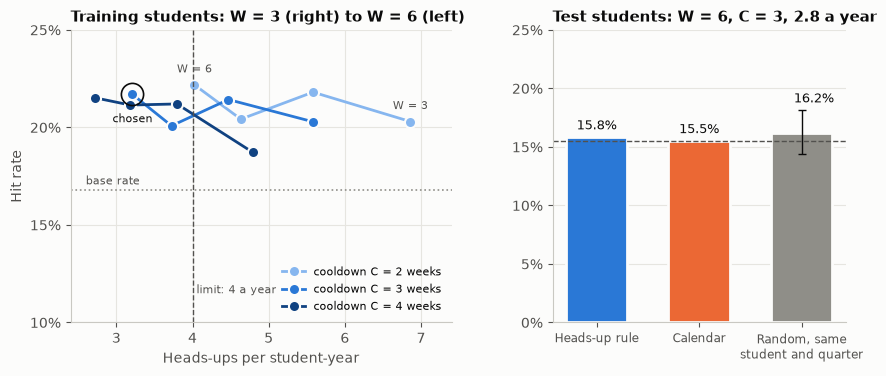

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"wspace": 0.3, "width_ratios": [1.3, 1]})
ax = axes[0]
for C, col in zip(ex.C_GRID, ["#86b6ef", "#2a78d6", "#104281"]):
    g = grid[grid["cooldown_weeks"] == C].sort_values("weeks_out")
    ax.plot(g["alerts_per_student_year"], g["hit_rate"], lw=2, marker="o", ms=8, color=col,
            markeredgecolor=SURFACE, markeredgewidth=1.5, label=f"cooldown C = {C} weeks")
g2 = grid[grid["cooldown_weeks"] == ex.C_GRID[0]].sort_values("weeks_out")
for _, r in g2.iloc[[0, -1]].iterrows():
    ax.annotate(f"W = {int(r['weeks_out'])}", (r["alerts_per_student_year"], r["hit_rate"]),
                textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8, color=INK2)
ch = grid[(grid["weeks_out"] == hu["chosen"]["weeks_out"]) & (grid["cooldown_weeks"] == hu["chosen"]["cooldown_weeks"])].iloc[0]
ax.plot(ch["alerts_per_student_year"], ch["hit_rate"], marker="o", ms=16, mfc="none", mec=INK, mew=1.2)
ax.annotate("chosen", (ch["alerts_per_student_year"], ch["hit_rate"]), textcoords="offset points",
            xytext=(0, -20), ha="center", fontsize=8, color=INK)
ax.axvline(ex.MAX_ALERTS_PER_YEAR, color=INK2, ls="--", lw=1)
ax.text(ex.MAX_ALERTS_PER_YEAR, 0.115, " limit: 4 a year", color=INK2, fontsize=8)
ax.axhline(grid["base_rate"].iloc[0], color=GRAY, ls=":", lw=1.2)
ax.text(2.6, grid["base_rate"].iloc[0] + 0.003, "base rate", color=INK2, fontsize=8)
ax.set_xlim(2.4, 7.4)
ax.set_ylim(0.10, 0.25)
ax.set_yticks([0.10, 0.15, 0.20, 0.25])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_xlabel("Heads-ups per student-year")
ax.set_ylabel("Hit rate")
ax.set_title("Training students: W = 3 (right) to W = 6 (left)")
ax.legend(loc="lower right", fontsize=8)

ax = axes[1]
names = ["Heads-up rule", "Calendar", "Random, same\nstudent and quarter"]
vals = [t["method"]["hit_rate"], t["fixed_calendar"]["hit_rate"], t["random_same_student_and_quarter"]["hit_rate"]]
ci = t["random_same_student_and_quarter"]["ci"]
xs = np.arange(3)
ax.bar(xs, vals, color=[BLUE, ORANGE, GRAY], width=0.6, edgecolor=SURFACE, linewidth=2)
ax.errorbar(xs[2], vals[2], yerr=[[vals[2] - ci[0]], [ci[1] - vals[2]]], color=INK, capsize=3, lw=1)
for x, v in zip(xs, vals):
    ax.text(x + (0.12 if x == 2 else 0), (ci[1] if x == 2 else v) + 0.004, pct(v), ha="center", va="bottom", color=INK, fontsize=9)
ax.axhline(t["method"]["base_rate"], color=INK2, ls="--", lw=1)
ax.set_xticks(xs, names, fontsize=8.5)
ax.set_ylim(0, 0.25)
ax.set_yticks([0, 0.05, 0.10, 0.15, 0.20, 0.25])
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.0f}%"))
ax.set_title(f"Test students: W = {hu['chosen']['weeks_out']}, C = {hu['chosen']['cooldown_weeks']}, "
             f"{t['method']['asks_per_student_year']:.1f} a year")
ax.grid(axis="x", visible=False)
plt.show()

In [14]:
rows = []
for h in res["heads_up"]["splits"]:
    tt = h["test"]
    rows.append({"seed": h["seed"], "W": h["chosen"]["weeks_out"], "C": h["chosen"]["cooldown_weeks"],
                 "heads-ups per student-year": tt["method"]["asks_per_student_year"],
                 "hit rate": tt["method"]["hit_rate"], "calendar": tt["fixed_calendar"]["hit_rate"],
                 "difference": tt["method_minus_calendar"]["difference"],
                 "difference 95% interval": f"{100 * tt['method_minus_calendar']['ci'][0]:.1f} to {100 * tt['method_minus_calendar']['ci'][1]:.1f} points"})
pd.DataFrame(rows).round(3)

,seed,W,C,heads-ups per student-year,hit rate,calendar,difference,difference 95% interval
0,20261114,6,3,2.810,0.158,0.155,0.004,-3.4 to 5.0 points
1,20261214,6,3,3.038,0.178,0.156,0.023,-2.2 to 7.3 points
2,20261314,5,3,3.049,0.173,0.142,0.031,-1.5 to 8.3 points
3,20261414,6,2,3.949,0.166,0.141,0.025,-2.0 to 8.7 points
4,20261514,6,2,3.890,0.167,0.175,-0.008,-5.3 to 4.0 points


The training hit rate falls back toward the base rate on new students, and in every split the interval for the difference from the calendar includes zero.

## 8. Check at the door

Students whose PHQ-2 was 3 or more in one of their four learning weeks: how many does the drift rule never ask in weeks 5 to 12?

In [15]:
door = res["door_check"]
pd.DataFrame({
    "high in any learning week": door["any_high_learning_week"],
    "average of 3 or more over learning weeks": door["mean_high_over_learning_weeks"],
    "everyone else": door["comparison_not_high_at_start"],
}).T

,students,missed_by_drift_rule,share_missed,still_high_in_weeks_5_to_12,missed_and_still_high_in_weeks_5_to_12
high in any learning week,37.0,11.0,0.297297,29.0,10.0
average of 3 or more over learning weeks,12.0,3.0,0.250000,11.0,3.0
everyone else,175.0,58.0,0.331429,25.0,5.0


About three in ten of the students who start high get no ask for two months. The rule skips other students at about the same rate, so it does not pick out the students who start high. This is the case the eight questions at setup are for.

## 9. Secondary checks

Single signals on their own, and the platform-only signals (steps and late-night audio on iPhone; texts, calls and nearby conversation on Android).

In [16]:
display(pd.DataFrame(res["single_signal_auc"]).T.round(3))
plat = []
for name in ["ios", "android"]:
    r = res["platform_secondary"][name]
    for tag in ["core_signals", "core_plus_platform"]:
        c = r[tag]
        plat.append({"group": name, "students": r["students"], "signals": tag,
                     "asks per student-year": c["budget_asks_per_student_year"], "rule hit rate": c["hit_rate"],
                     "calendar": c["calendar_hit_rate"],
                     "random, same student and quarter": c["random_same_student_and_quarter_hit_rate"]})
display(pd.DataFrame(plat).round(3))
pd.DataFrame({**res["platform_secondary"]["ios"]["single_signal_auc"],
              **res["platform_secondary"]["android"]["single_signal_auc"]}).T.round(3)

,auc,weeks,share_weeks_out
sleep,0.521,16886.0,0.230
bedtime,0.516,16861.0,0.215
night_phone,0.548,16886.0,0.214
time_with_others,0.505,16829.0,0.383
places,0.532,16886.0,0.590
movement,0.532,16886.0,0.251


,group,students,signals,asks per student-year,rule hit rate,calendar,"random, same student and quarter"
0,ios,183,core_signals,20.728,0.155,0.135,0.157
1,ios,183,core_plus_platform,26.562,0.150,0.135,0.153
2,android,30,core_signals,25.136,0.117,0.101,0.120
3,android,30,core_plus_platform,29.407,0.114,0.101,0.114


,auc,weeks,share_weeks_out
steps,0.529,12850.0,0.489
night_audio,0.534,13555.0,0.214
sms_out,0.572,2605.0,0.268
calls_out,0.444,2605.0,0.239
conversation,0.627,2605.0,0.370


## 10. Summary

In [17]:
print(ex.make_headline(res))
print()
for c in ex.make_caveats(res):
    print("-", c)

At 21 asks per student-year, 14.6% of the drift rule's asks landed on weeks with a high mood score against 12.9% for a fixed calendar, but random weeks from the same student in the same three months did as well (14.9%), so the rule found harder stretches and did no better than chance at picking the week.

- Mood scores stand in for a note being right. They cannot show whether a note helped a family.
- The students are Dartmouth undergraduates followed from 2017 to 2022, through the pandemic. Steady is meant for high school students.
- The label is two PHQ-4 items answered on the phone, counted as high at 3 or more. Only 74% of monitored weeks have one.
- The phone signals are the study's own features. Steady would record different ones, and typing, tone and music were not available.
- The personal range is learned in each student's first four valid weeks and then frozen, so it drifts: the rule asked in 26% of weeks in year one and 61% in year three.
- At k = 1.0 the rule asks in 41% of

The full write-up is in `results/exp1/results.md`, and every number is in `results/exp1/results.json`.